<a href="https://colab.research.google.com/github/carn51/Assignment-1/blob/main/fyp_12_10_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [293]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew
from scipy.stats import kurtosis
import numpy as np
import seaborn as sns

In [294]:
df = pd.DataFrame(pd.read_csv('/content/Schizophrenia _Dataset(5).csv'))
df.head()

,Diagnosis,Anhedonia,Apathy,Appetite,Concentration,Content,Delay,Delusion,Dep_Mood,Focus,...,Race,Rumination,Sex,Sleep,Stress,Suspicious,Tension,Tired,Unusual_Thought,Withdrawal
0,1,4.501446,3.056575,9.283891,8.305502,0.006142,Yes,1.170842,8.177884,8.305502,...,White,5.041432,Female,6.552082,5.915492,3.991749,6.371877,4.537270,3.744410,5.242819
1,0,5.432608,0.307721,25.809400,5.060206,0.062209,Yes,2.272548,11.162913,5.060206,...,White,4.656790,Male,5.558434,4.008265,NaN,2.238665,6.113746,0.720458,3.797242
2,0,6.557500,-1.412208,24.842012,6.504229,0.071532,No,1.439095,5.887363,6.504229,...,Black,7.290494,Female,5.787561,7.177926,NaN,6.992499,5.557374,-0.491255,4.421288
3,0,5.429568,1.686157,24.175853,6.994948,0.278345,No,1.380185,8.943851,6.994948,...,White,6.759339,Female,6.787287,2.866815,NaN,4.018286,6.136269,0.765388,2.299562
4,1,5.099846,-0.612506,45.808490,5.869212,0.004214,Yes,1.237976,6.741627,5.869212,...,Black,6.190019,Male,7.748312,6.798220,5.103103,5.063542,4.213723,0.705895,6.547707


In [295]:
df.shape

(5000, 27)

In [296]:
df.dropna().shape

(871, 27)

Missingness Analysis

In [297]:
#proportion of cells missing total
df.isnull().sum().sum() / (df.shape[0] * df.shape[1])

np.float64(0.044007407407407405)

In [298]:
#missiing value count per column
df.isnull().sum()

,0
Diagnosis,0
Anhedonia,0
Apathy,0
Appetite,0
Concentration,0
Content,0
Delay,0
Delusion,0
Dep_Mood,0
Focus,0


In [299]:
#proportion of rows with more than 2 missing values that are schizophrenic
two_plus_missing_cols = df.mask(df.isnull().sum(axis = 1) > 2)
print(two_plus_missing_cols['Diagnosis'].sum() / df.shape[0])


#compared to proportion overall
df['Diagnosis'].sum() / df.shape[0]
#the difference seems insignificant

0.4904


np.float64(0.5058)

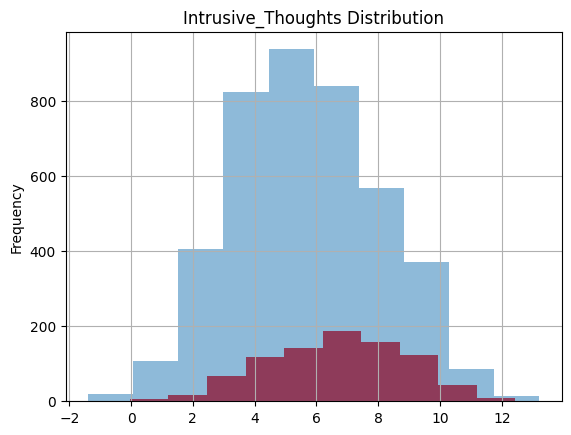

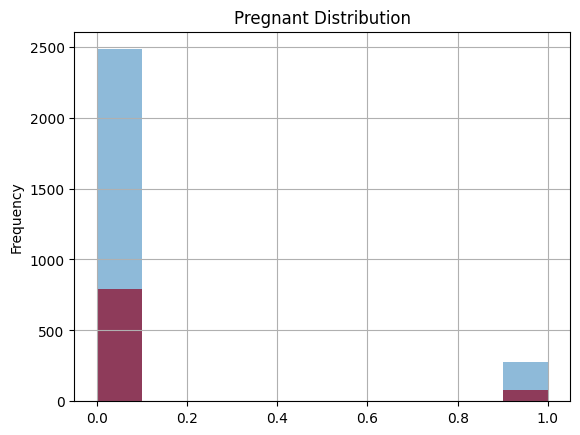

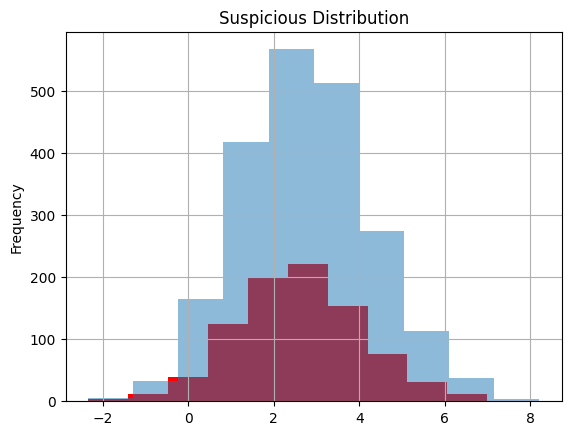

In [300]:
missing_col_list = ['Intrusive_Thoughts', 'Pregnant', 'Suspicious']

for missing_col in missing_col_list:
  plt.title(f'{missing_col} Distribution')
  plt.ylabel('Frequency')
  df.dropna()[missing_col].hist(color = 'red')
  two_plus_missing_cols[missing_col].hist(alpha = 0.5)
  plt.show()

In [301]:
#dropping high missingness columns for now
df = df.drop(columns = ['Pregnant', 'Intrusive_Thoughts', 'Suspicious'])
df.head(3)

,Diagnosis,Anhedonia,Apathy,Appetite,Concentration,Content,Delay,Delusion,Dep_Mood,Focus,...,Psychomotor,Race,Rumination,Sex,Sleep,Stress,Tension,Tired,Unusual_Thought,Withdrawal
0,1,4.501446,3.056575,9.283891,8.305502,0.006142,Yes,1.170842,8.177884,8.305502,...,3.854579,White,5.041432,Female,6.552082,5.915492,6.371877,4.537270,3.744410,5.242819
1,0,5.432608,0.307721,25.809400,5.060206,0.062209,Yes,2.272548,11.162913,5.060206,...,5.821110,White,4.656790,Male,5.558434,4.008265,2.238665,6.113746,0.720458,3.797242
2,0,6.557500,-1.412208,24.842012,6.504229,0.071532,No,1.439095,5.887363,6.504229,...,7.893102,Black,7.290494,Female,5.787561,7.177926,6.992499,5.557374,-0.491255,4.421288


ID column

In [302]:
df['ID'] = np.arange(0, len(df.index), 1)

Outliers

In [303]:
#code to show df of all outliers with intermediate function

df_num = df.select_dtypes(include = ['number'])

def univariate_outliers_df(df_num, col):
  outliers = []
  for idx, val in enumerate(df_num[col]):
    if val > (df_num[col].mean() + (3 * df_num[col].std())):
      #as a check of number
      outliers.append(idx)
  return df_num.iloc[outliers]

outlier_df_list = []

for cols in df_num.columns:
  outlier_df_list.append(univariate_outliers_df(df, cols))

outlier_df_final = pd.concat(outlier_df_list, axis = 0)
display(outlier_df_final)

,Diagnosis,Anhedonia,Apathy,Appetite,Concentration,Content,Delay,Delusion,Dep_Mood,Focus,...,Race,Rumination,Sex,Sleep,Stress,Tension,Tired,Unusual_Thought,Withdrawal,ID
1727,0,11.288607,0.314455,22.281110,6.535779,0.074097,No,0.513200,0.000000,6.535779,...,White,10.599673,Female,7.628965,4.024827,2.844018,5.062663,-0.315859,2.632904,1727
1865,0,11.603140,1.128291,30.286102,7.584974,0.186164,No,0.447183,7.766037,7.584974,...,White,8.648874,Female,7.101698,4.952958,4.027466,7.190131,1.750675,5.157132,1865
2102,0,11.326136,0.471849,48.001121,6.116657,0.132815,No,1.714730,0.000000,6.116657,...,White,9.278940,Female,5.893279,4.472117,3.128726,5.762602,0.138995,5.005872,2102
2666,0,11.255475,0.417478,19.407577,7.087778,0.014976,Yes,1.390472,9.134040,7.087778,...,White,4.065332,Male,6.637107,2.314909,1.532838,5.384118,-0.535850,3.516735,2666
2699,0,11.378754,1.837023,30.859452,7.258015,0.410995,Yes,4.159998,8.513310,7.258015,...,Hispanic,3.728205,Male,6.298757,1.951504,3.545074,4.788719,0.906728,2.597398,2699
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1946,1,7.037175,7.443897,38.421958,5.595710,0.011906,Yes,3.619649,0.000000,5.595710,...,Black,3.051894,Male,6.458187,3.298820,5.528268,5.468059,5.017221,8.480746,1946
2679,1,7.165833,1.835799,12.318433,7.290123,0.040339,Yes,3.867122,9.837023,7.290123,...,Black,2.177791,Male,6.902727,5.761274,5.161775,2.484063,3.448059,8.549491,2679
2821,1,8.112008,2.029541,15.749570,7.136619,0.016588,No,6.054157,5.653432,7.136619,...,White,4.045282,Male,7.434573,4.476539,5.681477,6.728447,3.268935,9.022207,2821
3053,1,7.184740,7.799039,17.846095,7.974002,0.208173,Yes,4.394719,8.312165,7.974002,...,Black,3.253363,Male,7.743037,7.446947,7.126585,5.903702,5.866849,8.411491,3053


In [304]:
#how many are dupes (minimum)
len(outlier_df_final) - len(set(outlier_df_final))

223

In [305]:
outlier_df_final['ID'].value_counts()

,count
ID,
4080,2
1267,2
4981,2
3053,2
55,2
...,...
1904,1
1946,1
2679,1


Miscellaneous drops

In [306]:
df['Tired'].idxmax()
df = df[df['ID'] != 153]

Drop rows with outliers

In [307]:
outlier_index = set(outlier_df_final['ID'])
df = df.drop(outlier_index, axis = 'index')
df.head()

,Diagnosis,Anhedonia,Apathy,Appetite,Concentration,Content,Delay,Delusion,Dep_Mood,Focus,...,Race,Rumination,Sex,Sleep,Stress,Tension,Tired,Unusual_Thought,Withdrawal,ID
0,1,4.501446,3.056575,9.283891,8.305502,0.006142,Yes,1.170842,8.177884,8.305502,...,White,5.041432,Female,6.552082,5.915492,6.371877,4.537270,3.744410,5.242819,0
1,0,5.432608,0.307721,25.809400,5.060206,0.062209,Yes,2.272548,11.162913,5.060206,...,White,4.656790,Male,5.558434,4.008265,2.238665,6.113746,0.720458,3.797242,1
2,0,6.557500,-1.412208,24.842012,6.504229,0.071532,No,1.439095,5.887363,6.504229,...,Black,7.290494,Female,5.787561,7.177926,6.992499,5.557374,-0.491255,4.421288,2
3,0,5.429568,1.686157,24.175853,6.994948,0.278345,No,1.380185,8.943851,6.994948,...,White,6.759339,Female,6.787287,2.866815,4.018286,6.136269,0.765388,2.299562,3
4,1,5.099846,-0.612506,45.808490,5.869212,0.004214,Yes,1.237976,6.741627,5.869212,...,Black,6.190019,Male,7.748312,6.798220,5.063542,4.213723,0.705895,6.547707,4


EDA

<Axes: >

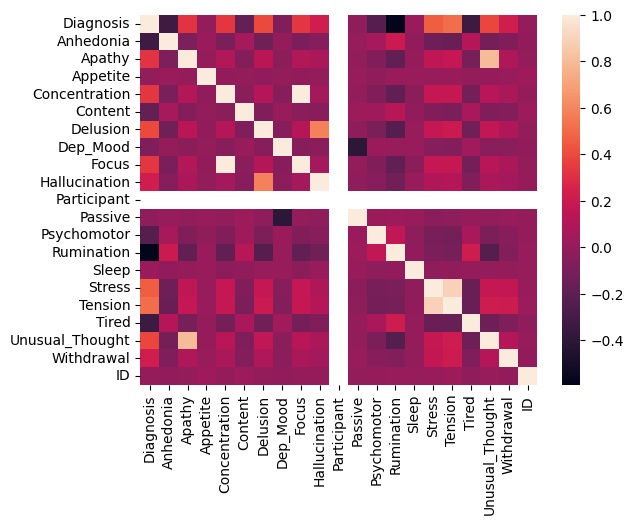

In [308]:
multicoll = sns.heatmap(df.select_dtypes(include = ['number']).corr())
multicoll

High mcl pairs

In [309]:
mcl_matrix = df.select_dtypes(include = ['number']).corr()
high_corr = np.abs(np.triu(mcl_matrix)) > 0.4

for row in range(0, 20):
  print(np.where(high_corr[row]))

(array([ 0, 13, 15, 16]),)
(array([1]),)
(array([ 2, 18]),)
(array([3]),)
(array([4, 8]),)
(array([5]),)
(array([6, 9]),)
(array([ 7, 11]),)
(array([8]),)
(array([9]),)
(array([], dtype=int64),)
(array([11]),)
(array([12]),)
(array([13]),)
(array([14]),)
(array([15, 16]),)
(array([16]),)
(array([17]),)
(array([18]),)
(array([19]),)


Scatter plots

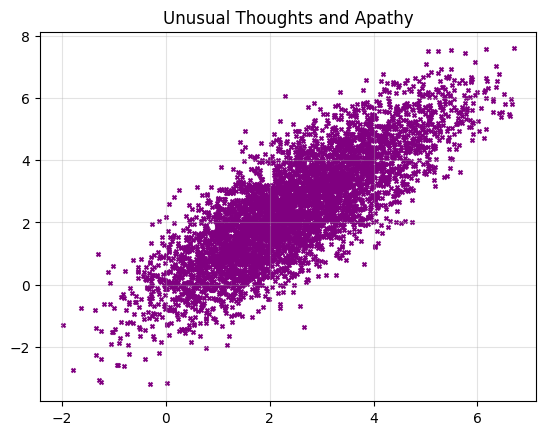

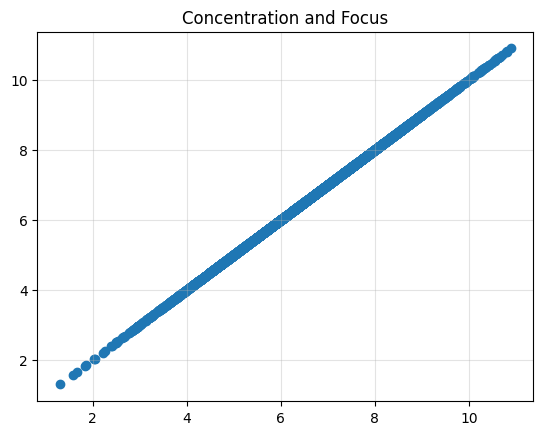

In [310]:
#ignore diags, first within each list
#2 and 18
plt.title('Unusual Thoughts and Apathy')
plt.grid(alpha = 0.35)
plt.scatter(df['Unusual_Thought'], df['Apathy'],
            s = 8, marker = 'x', color = 'purple')
plt.show()

plt.title('Concentration and Focus')
plt.grid(alpha = 0.35)
plt.scatter(df['Concentration'], df['Focus'])
plt.show()    #DROP one

#plt.title('Delusion and Hallucination')
#plt.scatter(df['Delusion'], df['Hallucination'])
#plt.show()

#plt.title('')
#plt.scatter(df['Dep_Mood'], df['Passive'])
#plt.show()

In [311]:
df = df.drop(columns= ['Concentration'])

Prep for pipeline

In [312]:
df.dtypes

,0
Diagnosis,int64
Anhedonia,float64
Apathy,float64
Appetite,float64
Content,float64
Delay,object
Delusion,float64
Dep_Mood,float64
Focus,float64
Hallucination,float64


In [313]:
#filter out 'values too big for float'... assuing from same column as earlier
df['Tired'] = df['Tired'].replace(np.inf, 'nan').dropna()
df['Tired'] = df['Tired'].astype(float)

In [314]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

In [315]:
X= df.drop(columns = ['Diagnosis', 'ID'])
y = df['Diagnosis']

In [316]:
num_cols = X.select_dtypes(include = ['number']).columns
cat_cols = X.select_dtypes(include = ['object']).columns

In [317]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=23)

**feature alignment check**

In [318]:
display(pipe)    #should be 29... if yes assume order of feat importances matches

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num_prep_ct',
                                                  Pipeline(steps=[('num_imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Anhedonia', 'Apathy', 'Appetite', 'Content', 'Delusion', 'Dep_Mood',
       'Focus', 'Hallucination', 'Participant', 'Passive', 'Psychomotor',
       'Rumination', 'Sleep', 'Stress', 'Tension', 'Tired', 'Unusual_Thought',
       'Withdrawal'],
      dtype='object')),
                                                 ('cat_prep_ct',
                                                  Pipeline(steps=[('cat_imputer',
                                                                   SimpleImputer(strategy='constant')),
                                                                  ('encoder',
                                                                   OneHotEncoder(sparse_output=False))]),
                                                  Index(['Delay', 'Housing', 'Race', 'Sex'], dtype='object'))])),
                ('rf_cat', RandomForestClassifier())])

In [319]:
pipe[-1]

RandomForestClassifier()

Pipeline --> RF for importances

In [359]:
num_pipe = Pipeline(steps = [
    ('num_imputer', SimpleImputer()),
    ('scaler', StandardScaler())
])

cat_pipe = Pipeline(steps = [
    ('cat_imputer', SimpleImputer(strategy='constant')),
    ('encoder', OneHotEncoder(sparse_output = False))
])

prep_pipe = ColumnTransformer(transformers= [
    ('num_prep_ct', num_pipe, num_cols),
    ('cat_prep_ct',cat_pipe, cat_cols)
]).set_output(transform="pandas")

pipe = Pipeline(steps = [
    ('preprocessor', prep_pipe),
    ('rf_cat', RandomForestClassifier(n_estimators = 200))
])

pipe.fit(X_train, y_train)
pipe.predict(X_test)

print(prep_pipe)

ColumnTransformer(transformers=[('num_prep_ct',
                                 Pipeline(steps=[('num_imputer',
                                                  SimpleImputer()),
                                                 ('scaler', StandardScaler())]),
                                 Index(['Anhedonia', 'Apathy', 'Appetite', 'Content', 'Delusion', 'Dep_Mood',
       'Focus', 'Hallucination', 'Participant', 'Passive', 'Psychomotor',
       'Rumination', 'Sleep', 'Stress', 'Tension', 'Tired', 'Unusual_Thought',
       'Withdrawal'],
      dtype='object')),
                                ('cat_prep_ct',
                                 Pipeline(steps=[('cat_imputer',
                                                  SimpleImputer(strategy='constant')),
                                                 ('encoder',
                                                  OneHotEncoder(sparse_output=False))]),
                                 Index(['Delay', 'Housing', 'Race', 'Sex'], dty

Accuracy etc

In [360]:
pipe.score(X_test, y_test)    #pretty accurate

0.9381551362683438

Plotting

In [346]:
feat_names = list(pipe[-1].feature_names_in_)
#print(len(list(pipe[-1].feature_names_n_)))
print(feat_names)

['num_prep_ct__Anhedonia', 'num_prep_ct__Apathy', 'num_prep_ct__Appetite', 'num_prep_ct__Content', 'num_prep_ct__Delusion', 'num_prep_ct__Dep_Mood', 'num_prep_ct__Focus', 'num_prep_ct__Hallucination', 'num_prep_ct__Participant', 'num_prep_ct__Passive', 'num_prep_ct__Psychomotor', 'num_prep_ct__Rumination', 'num_prep_ct__Sleep', 'num_prep_ct__Stress', 'num_prep_ct__Tension', 'num_prep_ct__Tired', 'num_prep_ct__Unusual_Thought', 'num_prep_ct__Withdrawal', 'cat_prep_ct__Delay_No', 'cat_prep_ct__Delay_Yes', 'cat_prep_ct__Housing_Stable', 'cat_prep_ct__Housing_Unstable', 'cat_prep_ct__Race_Asian', 'cat_prep_ct__Race_Black', 'cat_prep_ct__Race_Hispanic', 'cat_prep_ct__Race_White', 'cat_prep_ct__Sex_Female', 'cat_prep_ct__Sex_Male']


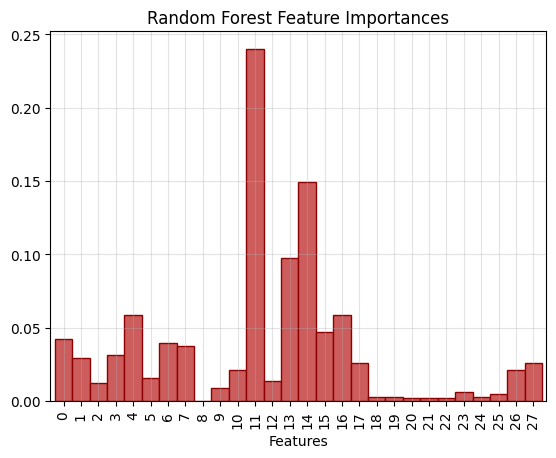

In [351]:
feat_importances = pd.Series(pipe[-1].feature_importances_)
plt.title('Random Forest Feature Importances')

ticks = list(np.arange(0, 28, 1))
labels = feat_names

feat_importances.plot(kind = 'bar',
                      width = 1, color = 'indianred', edgecolor = 'darkred')
plt.grid(alpha = 0.35)
plt.xlabel('Features')
#plt.xticks(ticks, pd.Series(labels))
plt.show()

Extracting a decision Tree

In [ ]:
pipe

Manually extracting

In [363]:
nlargest((list(zip(feat_names, feat_importances))), 20)

NameError: name 'nlargest' is not defined

Grid search???

Reduce features to see drop off in accuracy

---
bin

In [ ]:
#littles test
#!pip install pyampute
from pyampute.exploration.mcar_statistical_tests import MCARTest

littles = MCARTest(method = 'little')
print(littles.little_mcar_test(df.select_dtypes(include = []'number')))